# Housing Price Prediction Using Machine Learning


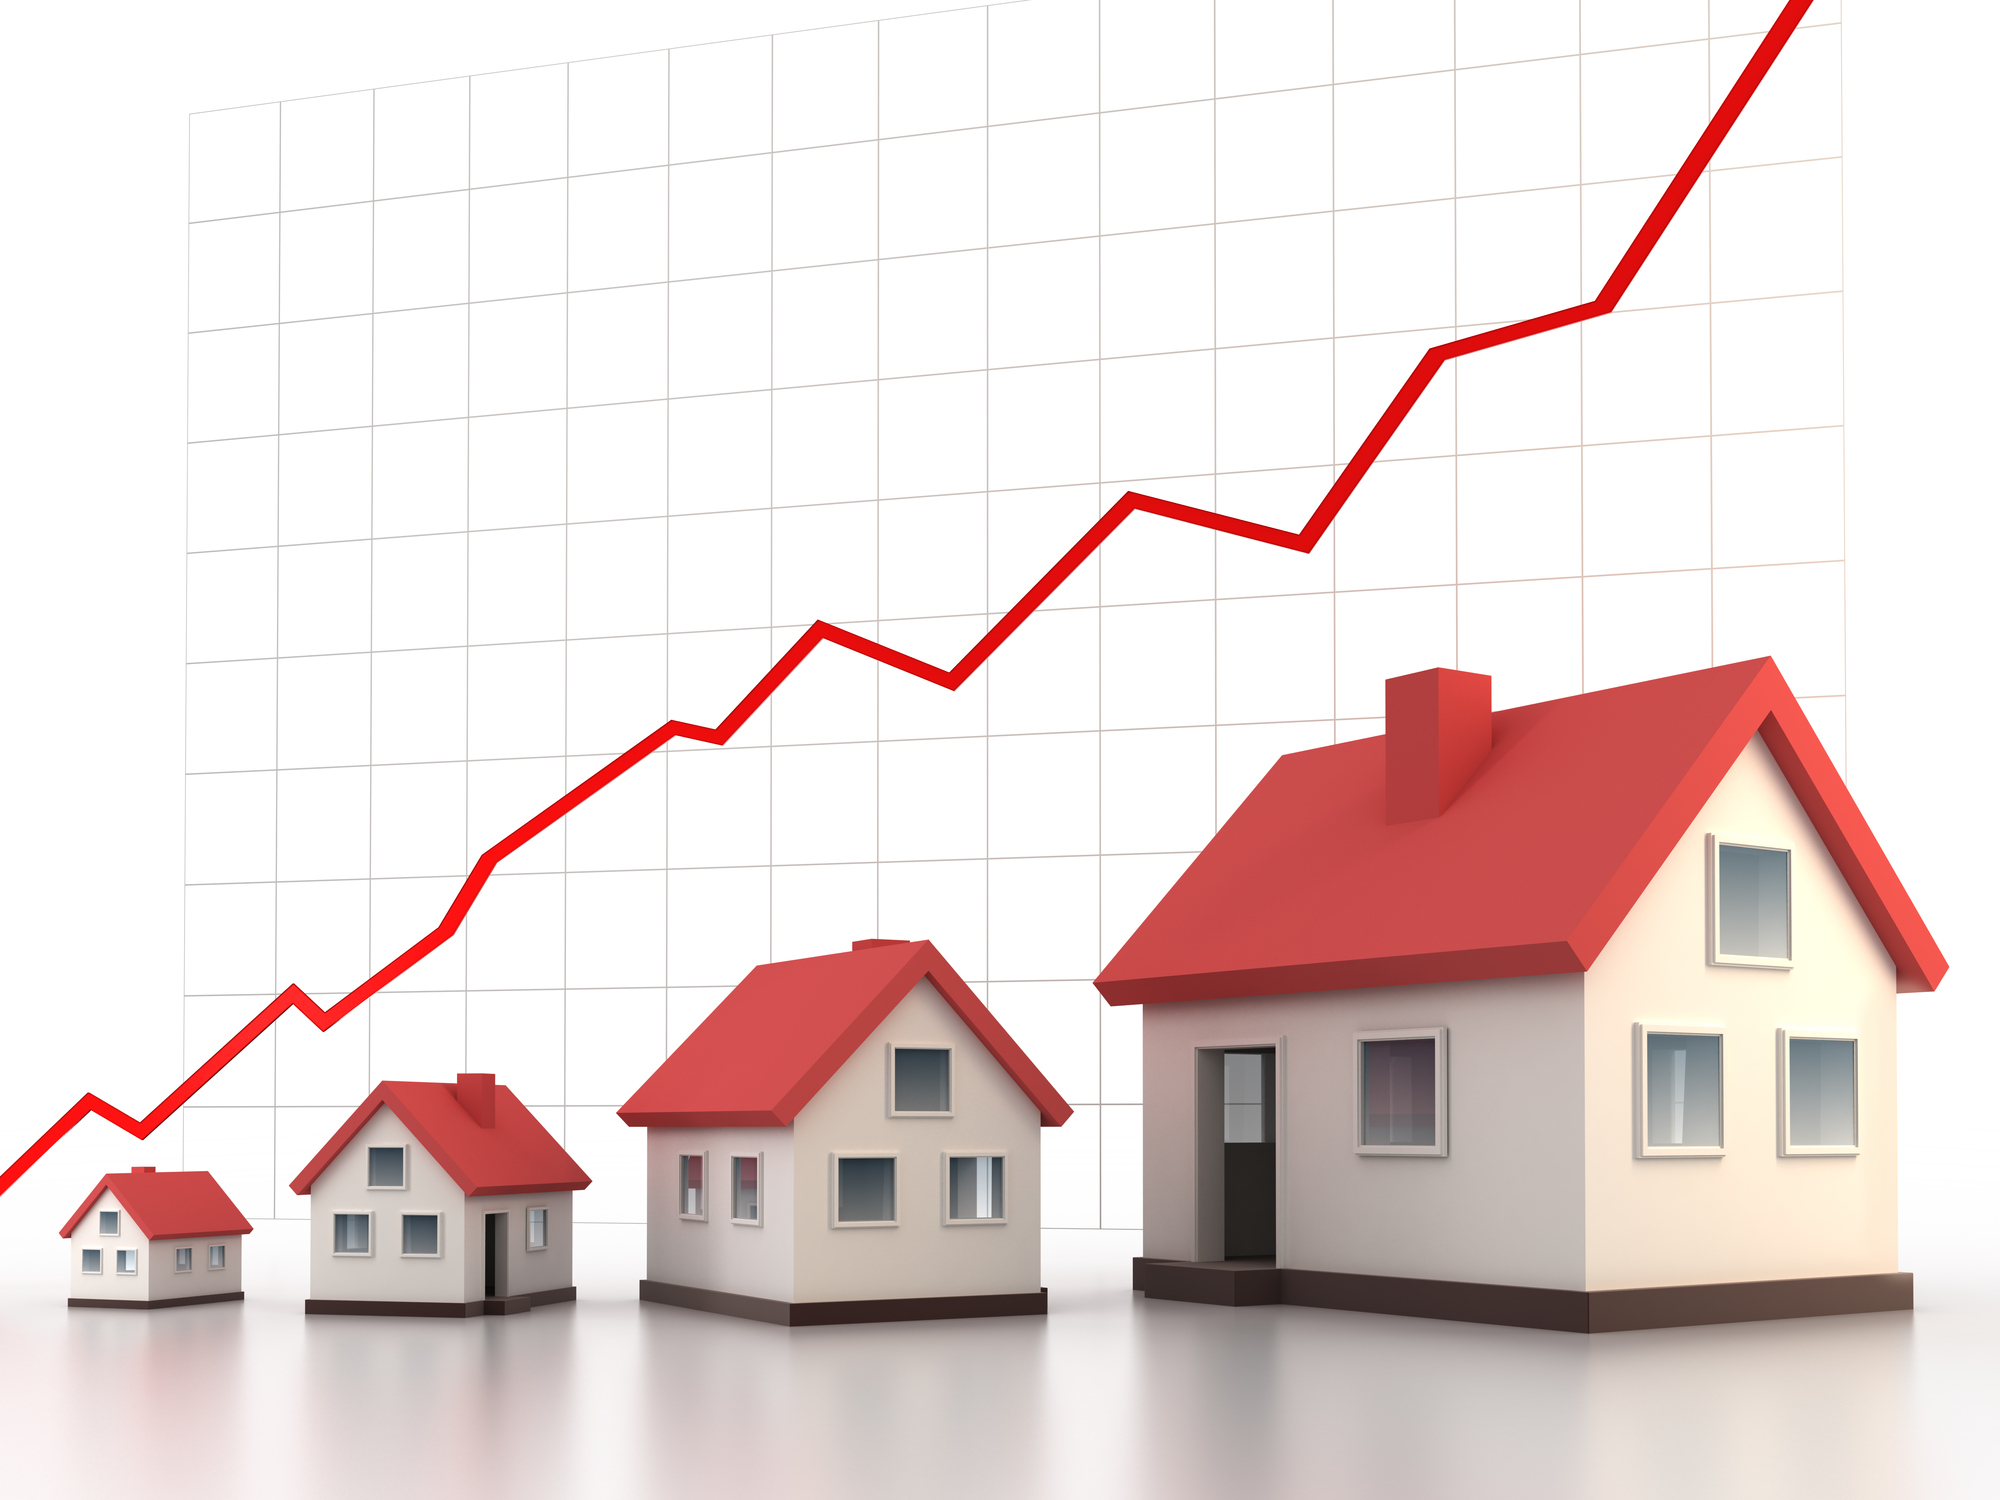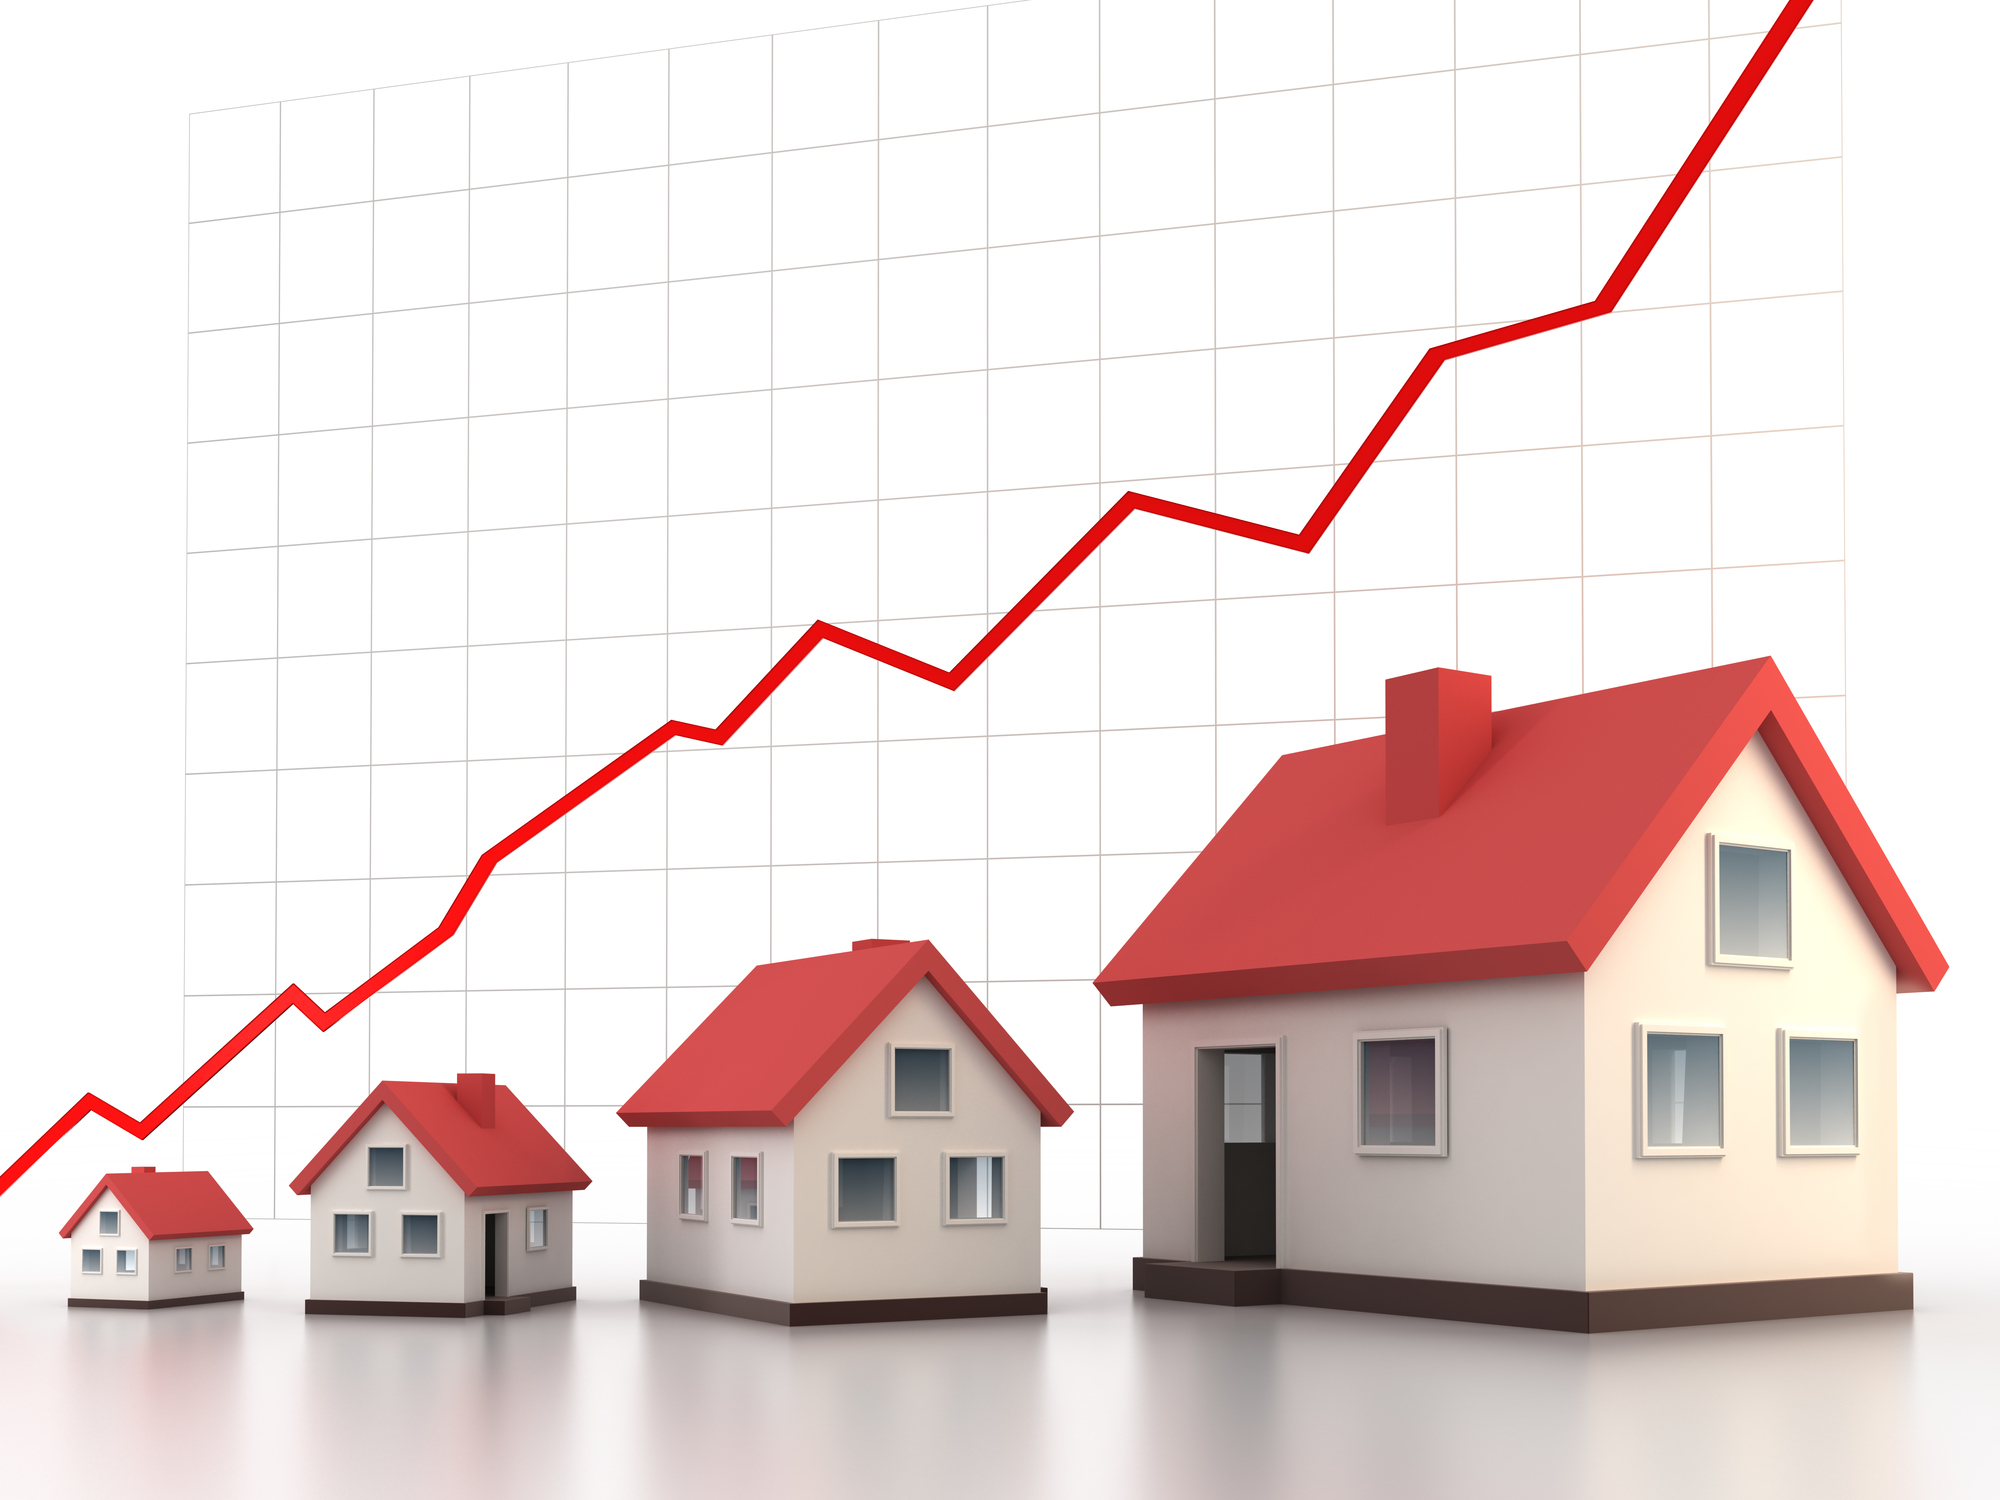

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing
import os
import time
import warnings
import pickle
warnings.filterwarnings('ignore')
print('All Module Loaded Successfully!!')

All Module Loaded Successfully!!


# Data Loading


In [61]:
data = fetch_california_housing()

In [62]:
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'feature_names', 'DESCR'])

In [63]:
df = pd.DataFrame(data.data,columns = data.feature_names)
df['MedHouseVal'] = data.target

In [64]:
data.target_names

['MedHouseVal']

In [65]:
df.sample(5)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
12464,3.9271,43.0,5.296188,0.994135,764.0,2.240469,38.58,-121.44,1.471
10570,5.7797,5.0,5.654321,1.092324,4656.0,2.499195,33.67,-117.67,3.092
12514,2.6250,51.0,5.387931,1.012931,452.0,1.948276,38.56,-121.45,1.212
4096,4.1656,24.0,4.687952,1.043373,1568.0,1.889157,34.15,-118.41,3.647
17428,4.2875,16.0,5.900463,0.990741,1486.0,3.439815,34.65,-120.47,1.507


In [66]:
print(data['DESCR'])

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

# Exploratory Data Analysis

In [67]:
rows, col = df.shape
print('No of Rows:', rows)
print('No of Cols:', col)

No of Rows: 20640
No of Cols: 9


In [68]:
df.sample(5)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
18287,10.3329,22.0,7.898396,1.042781,520.0,2.780749,37.37,-122.11,5.00001
584,5.4639,35.0,6.057534,0.958904,1004.0,2.750685,37.71,-122.08,2.38600
20280,3.2212,35.0,4.786372,1.016575,2726.0,5.020258,34.19,-119.19,1.80500
17816,6.8677,25.0,6.785455,0.985455,840.0,3.054545,37.40,-121.84,2.88500
20581,3.1534,20.0,5.444976,1.057416,459.0,2.196172,38.83,-122.21,1.23400


In [69]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [70]:
df.tail()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894


In [71]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [72]:
df.isna().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [73]:
# Missing value: No

In [74]:
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')

In [75]:
len(df.columns)

9

In [76]:
for i in range(len(df.columns)):
    print(i)

0
1
2
3
4
5
6
7
8


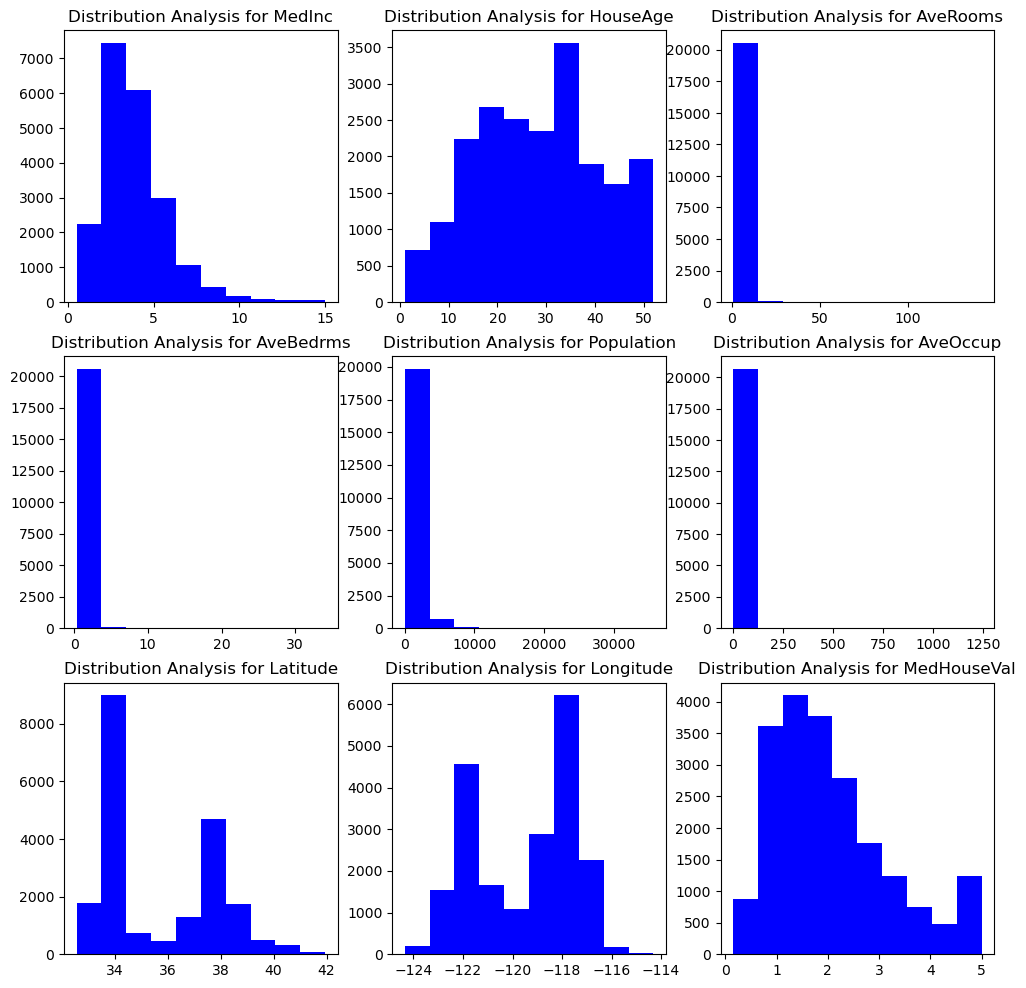

In [77]:
plt.figure(figsize=(12,12))
for i in range(len(df.columns)):
    plt.subplot(3,3,i+1)
    plt.title(f'Distribution Analysis for {df.columns[i]}')
    plt.hist(df[df.columns[i]], color = 'b')

plt.show()    

In [78]:
df.corr()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176,0.688075
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197,0.105623
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540,0.151948
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344,-0.046701
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773,-0.024650
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476,-0.023737
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664,-0.144160
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000,-0.045967
MedHouseVal,0.688075,0.105623,0.151948,-0.046701,-0.024650,-0.023737,-0.144160,-0.045967,1.000000


<Axes: >

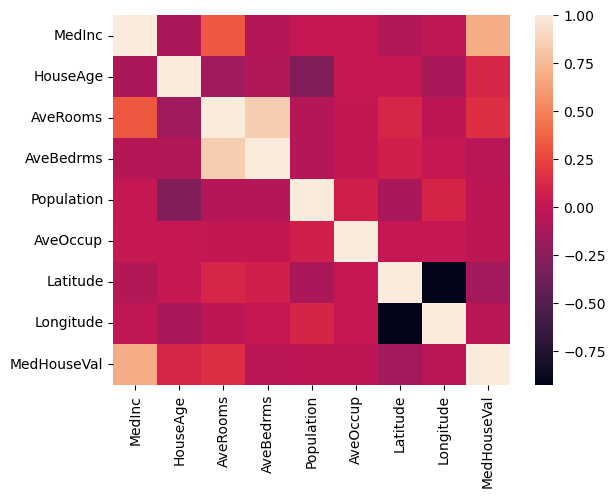

In [79]:
sns.heatmap(df.corr())

<Axes: title={'center': 'Correlation b/n Features'}>

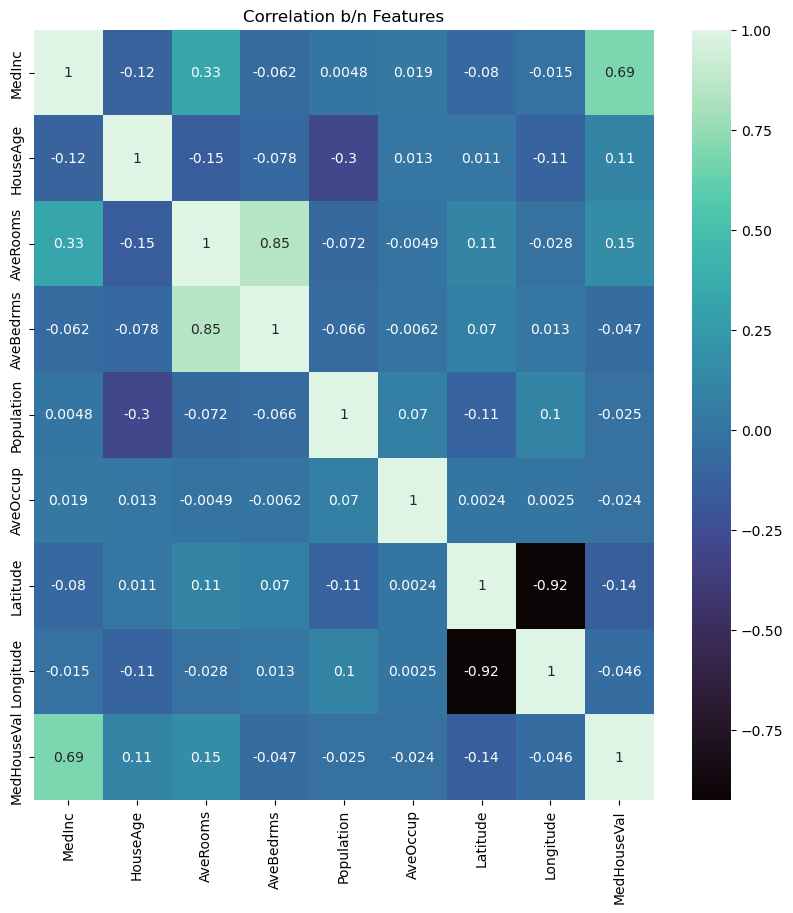

In [80]:
plt.figure(figsize=(10,10))
plt.title('Correlation b/n Features')
sns.heatmap(df.corr(), annot = True, cmap='mako')

# Data Preprocessing

In [81]:
X = df.iloc[:, :-2]
X

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85
...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43


In [82]:
Y = df['MedHouseVal']
Y

0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: MedHouseVal, Length: 20640, dtype: float64

In [83]:
# MIN_MAX_SCALER

In [84]:
scaler = MinMaxScaler()

In [85]:
scaled_X = scaler.fit_transform(X)

In [86]:
scaled_df = pd.DataFrame(scaled_X, columns=X.columns)

In [87]:
scaled_df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude
0,0.539668,0.784314,0.043512,0.020469,0.008941,0.001499,0.567481
1,0.538027,0.392157,0.038224,0.018929,0.067210,0.001141,0.565356
2,0.466028,1.000000,0.052756,0.021940,0.013818,0.001698,0.564293
3,0.354699,1.000000,0.035241,0.021929,0.015555,0.001493,0.564293
4,0.230776,1.000000,0.038534,0.022166,0.015752,0.001198,0.564293
...,...,...,...,...,...,...,...
20635,0.073130,0.470588,0.029769,0.023715,0.023599,0.001503,0.737513
20636,0.141853,0.333333,0.037344,0.029124,0.009894,0.001956,0.738576
20637,0.082764,0.313725,0.030904,0.023323,0.028140,0.001314,0.732200
20638,0.094295,0.333333,0.031783,0.024859,0.020684,0.001152,0.732200


In [88]:
scaled_df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,0.232464,0.541951,0.032488,0.022629,0.039869,0.001914,0.328572
std,0.131020,0.246776,0.017539,0.014049,0.031740,0.008358,0.226988
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.142308,0.333333,0.025482,0.019943,0.021974,0.001398,0.147715
50%,0.209301,0.549020,0.031071,0.021209,0.032596,0.001711,0.182784
75%,0.292641,0.705882,0.036907,0.022713,0.048264,0.002084,0.549416
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


# Train Test Part Data Divide

In [89]:
X_train, X_test, Y_train, Y_test = train_test_split(scaled_X, Y, test_size=0.1, random_state=32)

In [90]:
X_train.shape

(18576, 7)

In [91]:
X_test.shape

(2064, 7)

In [92]:
Y_train.shape

(18576,)

In [93]:
Y_test.shape

(2064,)

# Model Building ML

In [94]:
model = LinearRegression()

In [95]:
model.fit(X_train, Y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [96]:
Y_pred = model.predict(X_test)

In [97]:
compare_df = pd.DataFrame({'Actual Y': Y_test, 'Predicted Y': Y_pred})

In [98]:
compare_df

,Actual Y,Predicted Y
20038,0.52300,0.830969
17684,0.87500,1.171607
9720,2.53800,2.014867
17295,5.00001,4.142535
18736,0.98100,1.535928
...,...,...
12779,0.49800,0.990029
12771,0.67000,1.130043
15974,2.41900,2.563409
5100,1.42600,2.243695


# Model Evaluation

In [99]:
score = model.score(X_test, Y_test)
print('Model Score: ', score)

Model Score:  0.551362762499376


In [100]:
mae = mean_absolute_error(Y_test, Y_pred)
print('Mean Absolute Error', mae)

Mean Absolute Error 0.5677843233572075


In [101]:
mse = mean_squared_error(Y_test, Y_pred)
print('Mean Squared Error', mse)

Mean Squared Error 0.6052385210505213


In [102]:
rmse = root_mean_squared_error(Y_test, Y_pred)
print('Root Mean Squared Error', rmse)

Root Mean Squared Error 0.7779707713343229


# Final Model Checking

In [103]:
matrix_dict = {'Model Number':[], 'Model':[], 'Model Score':[], 'MAE':[], 'MSE':[], 'RMSE':[]}
for i in range(5000):
    X_train, X_test, Y_train, Y_test = train_test_split(scaled_X, Y, test_size=0.1, random_state=i)
    model = LinearRegression()
    model.fit(X_train, Y_train)
    Y_pred = model.predict(X_test)
    score = model.score(X_test, Y_test)
    mae = mean_absolute_error(Y_test, Y_pred)
    mse = mean_squared_error(Y_test, Y_pred)
    rmse = root_mean_squared_error(Y_test, Y_pred)
    
    matrix_dict['Model Number'].append(i)
    matrix_dict['Model'].append(model)
    matrix_dict['Model Score'].append(score)
    matrix_dict['MAE'].append(mae)
    matrix_dict['MSE'].append(mse)
    matrix_dict['RMSE'].append(rmse)
    print(f'Checking Model{i+1}')
    display(clear=True)

matrix_df = pd.DataFrame(matrix_dict)
print('Done')

Done


In [106]:
matrix_df

,Model Number,Model,Model Score,MAE,MSE,RMSE
0,0,LinearRegression(),0.539876,0.584250,0.632354,0.795207
1,1,LinearRegression(),0.539413,0.574266,0.619368,0.786999
2,2,LinearRegression(),0.502733,0.589630,0.668455,0.817591
3,3,LinearRegression(),0.568915,0.563485,0.580866,0.762146
4,4,LinearRegression(),0.533087,0.573290,0.587384,0.766410
...,...,...,...,...,...,...
4995,4995,LinearRegression(),0.500881,0.574729,0.642570,0.801605
4996,4996,LinearRegression(),0.500247,0.576966,0.693597,0.832825
4997,4997,LinearRegression(),0.505985,0.576654,0.662073,0.813678
4998,4998,LinearRegression(),0.517502,0.568705,0.611983,0.782293


In [107]:
matrix_df['Model Score'].max()

0.6053940148587416

In [108]:
matrix_df['Model Score'].min()

-17.627966718929827

In [109]:
final_model_df = matrix_df[matrix_df['Model Score'] == matrix_df['Model Score'].max()]

In [110]:
matrix_positive_df = matrix_df[matrix_df['Model Score']>=0.50]


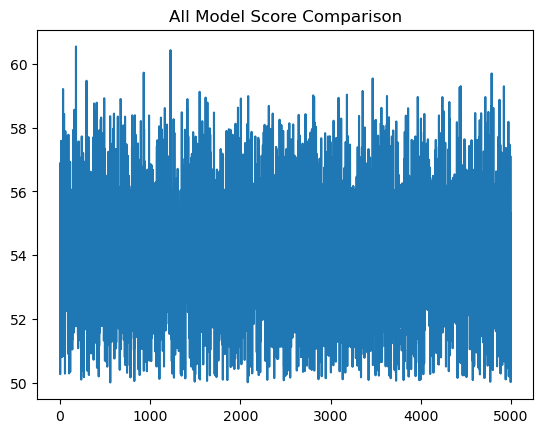

In [111]:
plt.plot(matrix_positive_df['Model Number'], matrix_positive_df['Model Score']*100)
plt.title('All Model Score Comparison')
plt.show()

# Final Model Save

In [112]:
final_model = final_model_df['Model']

In [113]:
final_model.values[0]

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [114]:
with open('chatgpt_for_house.pkl', 'wb') as f:
    pickle.dump(final_model.values[0], f)
print('Model Saved Successfully!!!')

Model Saved Successfully!!!


# Model Deployment on Website 

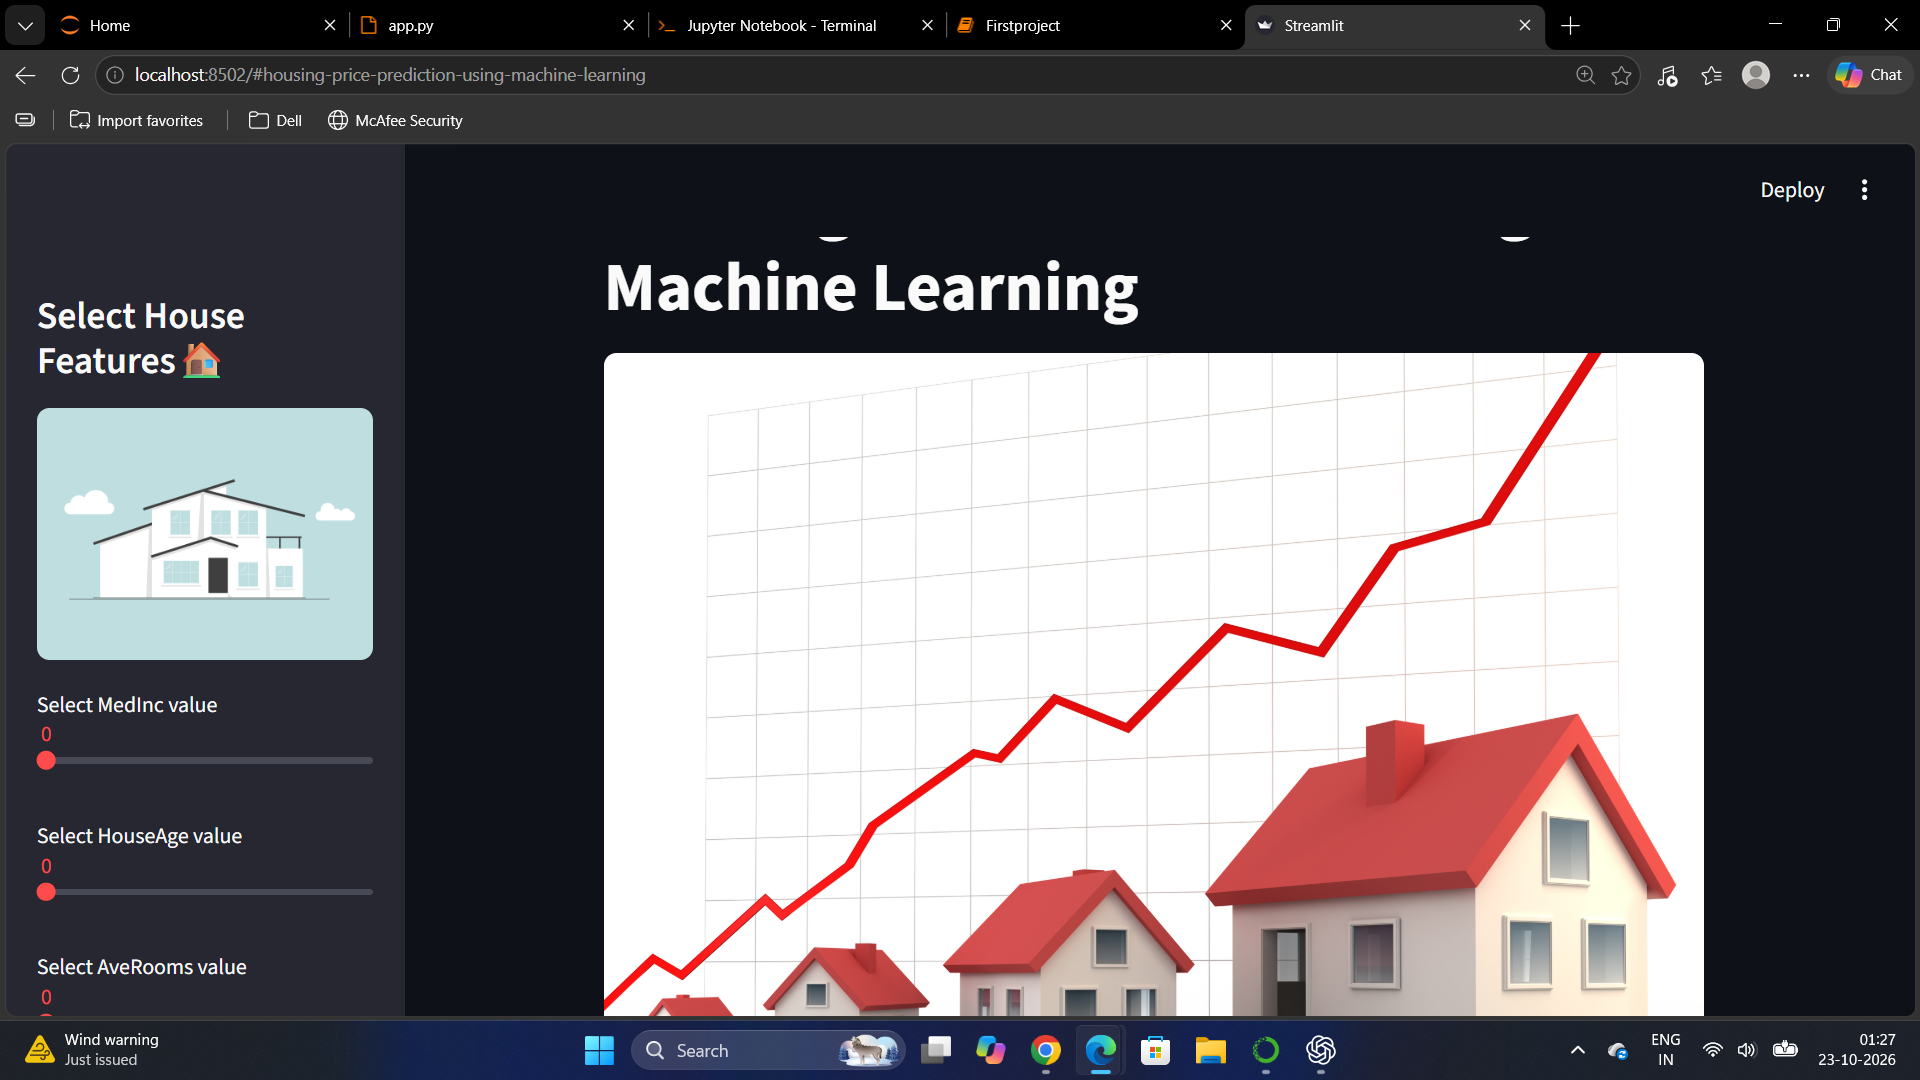